In [1]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
GPU available: False


In [2]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_data = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_data))
print("Test images:", len(test_data))
print("Classes:", train_data.classes)

image, label = train_data[0]
print("Image shape (channels, height, width):", image.shape)
print("Example image label:", train_data.classes[label])

100%|██████████| 170M/170M [30:53<00:00, 92.0kB/s]


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image shape (channels, height, width): torch.Size([3, 32, 32])
Example image label: frog


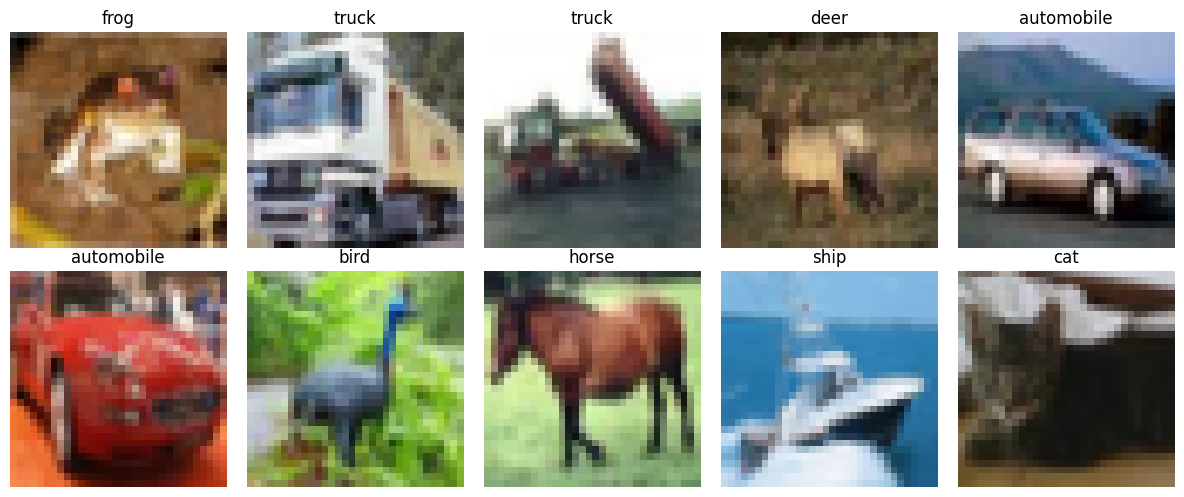

In [3]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:

import torch.nn as nn
import torch.nn.functional as F

class ImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

model = ImageClassifier()

print(model)


ImageClassifier(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [5]:

import torch.optim as optim
from torch.utils.data import DataLoader

# Prepare the data
train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training setup complete!")
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training setup complete!
Training batches: 782
Testing batches: 157


In [7]:

# Train the model
epochs = 3

for epoch in range(epochs):
    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(f"Epoch {epoch+1}/{epochs}, Loss: {average_loss:.4f}")

print("Training complete!")


Epoch 1/3, Loss: 1.1533
Epoch 2/3, Loss: 0.9785
Epoch 3/3, Loss: 0.8700
Training complete!


In [8]:

# Test the trained model
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 67.46%
Correct predictions: 6746/10000


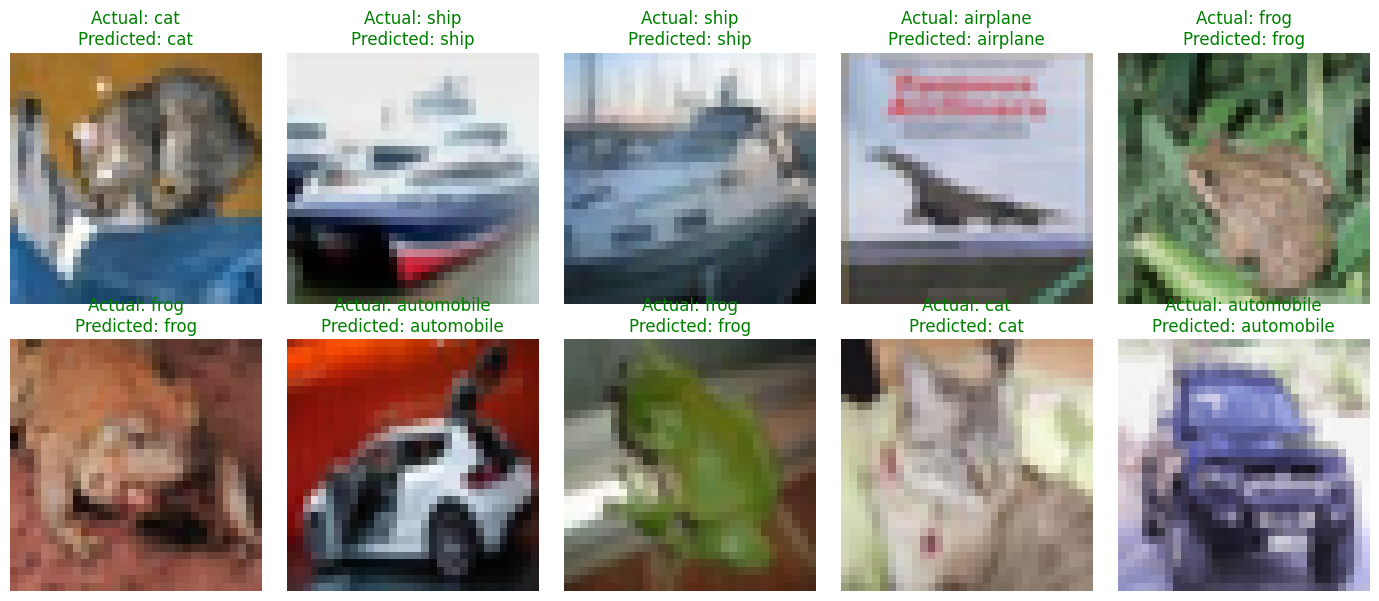

In [9]:

import matplotlib.pyplot as plt

model.eval()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

with torch.no_grad():
    for i, ax in enumerate(axes.flat):
        image, label = test_data[i]

        output = model(image.unsqueeze(0))
        predicted = output.argmax(1).item()

        ax.imshow(image.permute(1, 2, 0))

        actual_name = test_data.classes[label]
        predicted_name = test_data.classes[predicted]

        ax.set_title(
            f"Actual: {actual_name}\nPredicted: {predicted_name}",
            color="green" if predicted == label else "red"
        )

        ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:

# Save the trained model
torch.save(model.state_dict(), "cifar10_model.pth")

print("Model saved successfully!")


Model saved successfully!


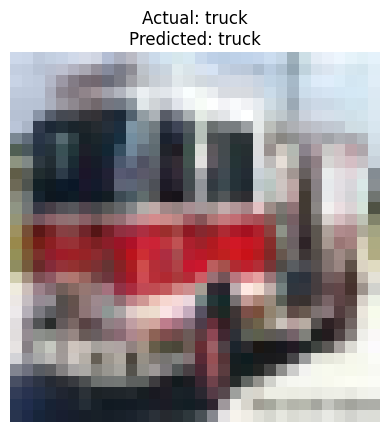

Prediction correct: True


In [11]:

import random
import matplotlib.pyplot as plt

# Select a random test image
index = random.randint(0, len(test_data) - 1)
image, label = test_data[index]

# Make a prediction
model.eval()

with torch.no_grad():
    output = model(image.unsqueeze(0))
    predicted = output.argmax(1).item()

# Display the result
plt.imshow(image.permute(1, 2, 0))
plt.axis("off")
plt.title(
    f"Actual: {test_data.classes[label]}\n"
    f"Predicted: {test_data.classes[predicted]}"
)
plt.show()

print("Prediction correct:", predicted == label)


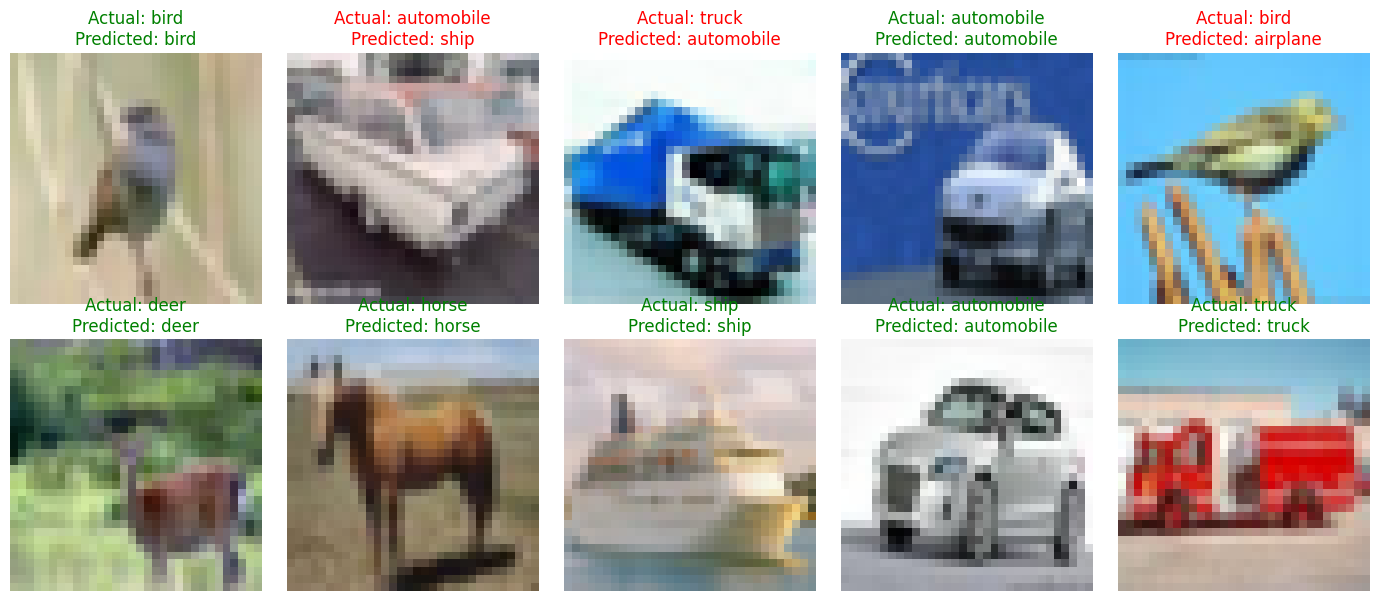

In [12]:

import random
import matplotlib.pyplot as plt

model.eval()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

with torch.no_grad():
    for ax in axes.flat:
        index = random.randint(0, len(test_data) - 1)
        image, label = test_data[index]

        output = model(image.unsqueeze(0))
        predicted = output.argmax(1).item()

        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(
            f"Actual: {test_data.classes[label]}\n"
            f"Predicted: {test_data.classes[predicted]}",
            color="green" if predicted == label else "red"
        )
        ax.axis("off")

plt.tight_layout()
plt.show()


In [13]:

# Continue training the existing model
epochs = 5

model.train()

for epoch in range(epochs):
    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(f"Epoch {epoch+1}/{epochs}, Loss: {average_loss:.4f}")

print("Additional training complete!")


Epoch 1/5, Loss: 0.7862
Epoch 2/5, Loss: 0.7132
Epoch 3/5, Loss: 0.6407
Epoch 4/5, Loss: 0.5829
Epoch 5/5, Loss: 0.5198
Additional training complete!


In [14]:

# Test accuracy after additional training
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Updated Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Updated Test Accuracy: 69.95%
Correct predictions: 6995/10000


In [15]:

# Save the improved model
torch.save(model.state_dict(), "cifar10_model_improved.pth")

print("Improved model saved successfully!")


Improved model saved successfully!


In [16]:

# Calculate accuracy for each class
model.eval()

class_correct = [0] * 10
class_total = [0] * 10

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted = outputs.argmax(1)

        for actual, prediction in zip(labels, predicted):
            class_total[actual.item()] += 1

            if actual.item() == prediction.item():
                class_correct[actual.item()] += 1

# Display accuracy for each category
for i, class_name in enumerate(test_data.classes):
    accuracy = 100 * class_correct[i] / class_total[i]
    print(f"{class_name}: {accuracy:.2f}%")


airplane: 76.50%
automobile: 75.60%
bird: 58.40%
cat: 59.00%
deer: 60.90%
dog: 68.60%
frog: 54.70%
horse: 80.00%
ship: 87.70%
truck: 78.10%


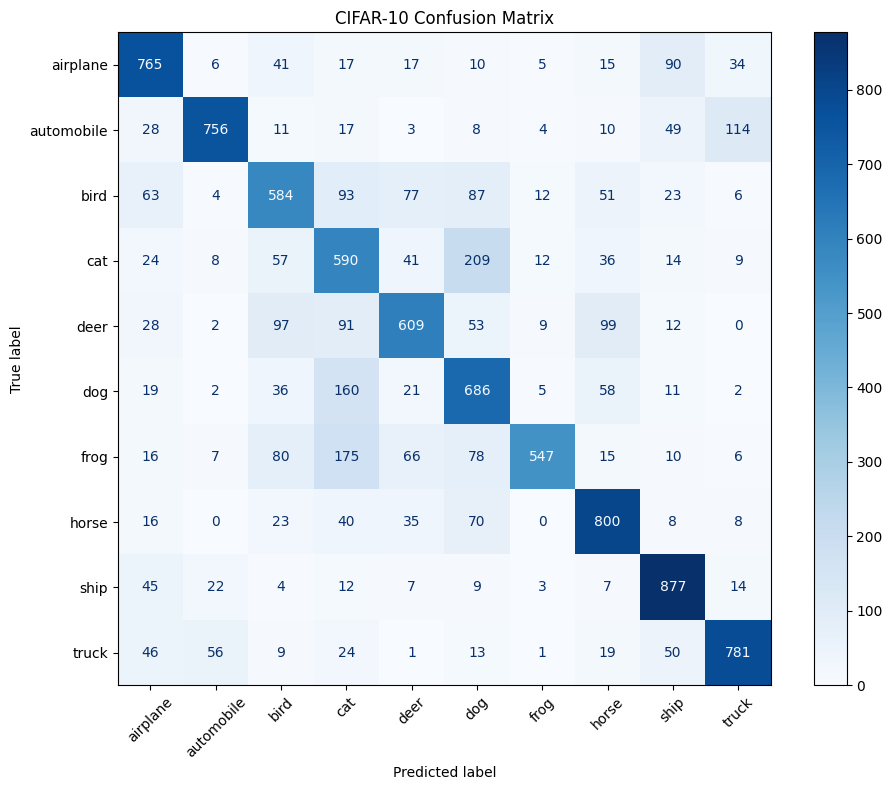

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted = outputs.argmax(1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predicted.tolist())

cm = confusion_matrix(all_labels, all_predictions)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_data.classes
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()


In [18]:

from sklearn.metrics import classification_report

print("CIFAR-10 Classification Report")
print("------------------------------")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_data.classes
    )
)


CIFAR-10 Classification Report
------------------------------
              precision    recall  f1-score   support

    airplane       0.73      0.77      0.75      1000
  automobile       0.88      0.76      0.81      1000
        bird       0.62      0.58      0.60      1000
         cat       0.48      0.59      0.53      1000
        deer       0.69      0.61      0.65      1000
         dog       0.56      0.69      0.62      1000
        frog       0.91      0.55      0.68      1000
       horse       0.72      0.80      0.76      1000
        ship       0.77      0.88      0.82      1000
       truck       0.80      0.78      0.79      1000

    accuracy                           0.70     10000
   macro avg       0.72      0.70      0.70     10000
weighted avg       0.72      0.70      0.70     10000



In [19]:

import pandas as pd
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(
    all_labels,
    all_predictions,
    target_names=test_data.classes,
    output_dict=True
)

# Convert to DataFrame
df = pd.DataFrame(report).transpose()

# Save results
df.to_csv("cifar10_classification_report.csv")

print("Classification report saved successfully!")

display(df)


Classification report saved successfully!


,precision,recall,f1-score,support
airplane,0.728571,0.7650,0.746341,1000.0000
automobile,0.876014,0.7560,0.811594,1000.0000
bird,0.619958,0.5840,0.601442,1000.0000
cat,0.484003,0.5900,0.531771,1000.0000
deer,0.694413,0.6090,0.648908,1000.0000
dog,0.560916,0.6860,0.617184,1000.0000
frog,0.914716,0.5470,0.684606,1000.0000
horse,0.720721,0.8000,0.758294,1000.0000
ship,0.766608,0.8770,0.818097,1000.0000
truck,0.801848,0.7810,0.791287,1000.0000
